# MatRisk AI — DS-1 Material Properties: Tested Baseline

**Purpose:** validate the supplied DS-1 CSV, audit basic physical consistency, and compare composition-only regression baselines for four numeric targets.

**Important limitations**
- This is a baseline experiment, not a claim of production-ready materials prediction.
- The split holds out entire chemical systems (element-set groups) to reduce chemical-system leakage. This is intentionally harder than a random row split.
- Formula features are elemental fractions plus number of elements. The parser supports flat formulas; it does not support parentheses, hydrates, or crystallographic structures.
- No crystal structure data is present in this CSV, so this notebook does **not** train a crystal graph neural network (CGNN).
- Metrics are computed from the actual supplied sample file. They may be weak; a simple mean baseline is the reference.


## 1. Load data and validate schema

In [6]:
from pathlib import Path
import re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, HistGradientBoostingRegressor

# Supports running from the repository root, ML/, or ML/notebooks/.
# Set MATRISK_DATA_ROOT if your data folder is elsewhere.
import os
DATA_ROOT = Path(os.environ["MATRISK_DATA_ROOT"]) if os.environ.get("MATRISK_DATA_ROOT") else None
DATA_CANDIDATES = []
if DATA_ROOT is not None:
    DATA_CANDIDATES += [DATA_ROOT / "DS1_material_properties_5500.csv"]
DATA_CANDIDATES += [
    Path("Data/DS1_material_properties_5500.csv"),
    Path("Data/raw/DS1_material_properties_5500.csv"),
    Path("../Data/DS1_material_properties_5500.csv"),
    Path("../Data/raw/DS1_material_properties_5500.csv"),
    Path("../../Data/DS1_material_properties_5500.csv"),
    Path("../../Data/raw/DS1_material_properties_5500.csv"),
    Path("data/raw/DS1_material_properties_5500.csv"),
    Path("data/external/DS1_material_properties_5500.csv"),
    Path("DS1_material_properties_5500.csv"),
    Path("/mnt/data/DS1_material_properties_5500.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find DS1_material_properties_5500.csv. Place it in data/raw/ "
        "or set DATA_PATH to its location."
    )
df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH, "| shape:", df.shape)
required = [
    "material_id", "formula", "n_elements", "crystal_system", "spacegroup_number",
    "formation_energy_per_atom_eV", "band_gap_eV", "bulk_modulus_GPa",
    "shear_modulus_GPa", "poisson_ratio", "density_g_cm3", "melting_point_K",
    "is_stable", "category"
]
missing_cols = sorted(set(required) - set(df.columns))
assert not missing_cols, f"Missing required columns: {missing_cols}"
display(df.head())


Loaded: ..\..\Data\raw\DS1_material_properties_5500.csv | shape: (5500, 18)


,material_id,formula,n_elements,crystal_system,spacegroup_number,category,formation_energy_per_atom_eV,energy_above_hull_eV,band_gap_eV,is_metal,bulk_modulus_GPa,shear_modulus_GPa,poisson_ratio,density_g_cm3,nsites,volume_A3,melting_point_K,is_stable
0,mp-121959,Ta3Au3H2,3,hexagonal,185,Chalcogenide,-0.6329,0.0175,1.940,0,26.87,13.47,0.2918,4.343,2,96.38,1142.0,1
1,mp-23248,Al3Rh4W3,3,hexagonal,171,Alloy,-1.2275,0.2124,0.000,1,50.30,33.94,0.2326,6.757,4,365.02,1244.0,0
2,mp-526982,Pd3Te3,2,cubic,227,Metal,0.1265,0.0993,0.000,1,256.03,125.93,0.2849,10.501,4,642.24,1178.0,0
3,mp-984775,Ne4Cd4,2,tetragonal,81,Nitride,-0.4655,0.0534,1.830,0,461.87,233.17,0.2888,1.754,32,820.52,1130.0,0
4,mp-965909,Al4Rh,2,cubic,202,Nitride,-0.6142,0.0501,1.264,0,187.79,148.00,0.1900,3.360,2,87.85,306.0,0


## 2. Data quality and physical consistency

In [7]:
audit = {
    "rows": int(len(df)),
    "columns": int(df.shape[1]),
    "missing_cells": int(df.isna().sum().sum()),
    "duplicate_full_rows": int(df.duplicated().sum()),
    "duplicate_material_id_rows": int(df["material_id"].duplicated().sum()),
    "unique_material_ids": int(df["material_id"].nunique()),
    "poisson_outside_open_bounds": int(((df.poisson_ratio <= -1) | (df.poisson_ratio >= 0.5)).sum()),
    "nonpositive_bulk_or_shear": int(((df.bulk_modulus_GPa <= 0) | (df.shear_modulus_GPa <= 0)).sum()),
    "nonpositive_density": int((df.density_g_cm3 <= 0).sum()),
    "stable_with_nonnegative_formation_energy": int(((df.is_stable == 1) & (df.formation_energy_per_atom_eV >= 0)).sum()),
}
E_from_G = 2 * df["shear_modulus_GPa"] * (1 + df["poisson_ratio"])
E_from_K = 3 * df["bulk_modulus_GPa"] * (1 - 2 * df["poisson_ratio"])
denom = np.maximum(np.maximum(np.abs(E_from_G), np.abs(E_from_K)), 1e-12)
relative_elastic_discrepancy = np.abs(E_from_G - E_from_K) / denom
audit["elastic_relation_relative_discrepancy_over_5pct"] = int((relative_elastic_discrepancy > 0.05).sum())
audit["elastic_relation_relative_discrepancy_median"] = float(relative_elastic_discrepancy.median())
display(pd.Series(audit, name="value").to_frame())
print("\nCategorical counts:")
for c in ["crystal_system", "category", "is_stable", "is_metal"]:
    if c in df:
        print(f"\n{c}\n", df[c].value_counts(dropna=False).head(15))


,value
rows,5500.000000
columns,18.000000
missing_cells,0.000000
duplicate_full_rows,0.000000
duplicate_material_id_rows,21.000000
unique_material_ids,5479.000000
poisson_outside_open_bounds,0.000000
nonpositive_bulk_or_shear,0.000000
nonpositive_density,0.000000
stable_with_nonnegative_formation_energy,369.000000



Categorical counts:

crystal_system
 crystal_system
cubic           1615
hexagonal       1107
orthorhombic     860
tetragonal       816
monoclinic       562
trigonal         378
triclinic        162
Name: count, dtype: int64

category
 category
Metal            1010
Oxide             773
Semiconductor     547
Ceramic           471
Intermetallic     451
Alloy             328
Nitride           304
Halide            267
Chalcogenide      249
Sulfide           239
Perovskite        215
Carbide           214
Silicate          168
Phosphide         157
Boride            107
Name: count, dtype: int64

is_stable
 is_stable
1    3478
0    2022
Name: count, dtype: int64

is_metal
 is_metal
0    3711
1    1789
Name: count, dtype: int64


## 3. Parse formulas into elemental fractions

In [8]:
# Deliberately simple parser for flat formulas such as Al2O3 or Ta3Au3H2.
# It rejects unsupported syntax rather than silently guessing.
FORMULA_TOKEN = re.compile(r"([A-Z][a-z]?)(\d*(?:\.\d+)?)")
def parse_flat_formula(formula):
    s = str(formula)
    tokens = FORMULA_TOKEN.findall(s)
    if not tokens or "".join(el + number for el, number in tokens) != s:
        return None
    counts = {}
    for element, number in tokens:
        counts[element] = counts.get(element, 0.0) + float(number or 1.0)
    return counts

parsed = df["formula"].map(parse_flat_formula)
parse_rate = float(parsed.notna().mean())
print(f"Formula parse success: {parse_rate:.1%} ({parsed.notna().sum()}/{len(df)})")
if parse_rate < 0.95:
    warnings.warn("Many formulas are unsupported. Review parser before trusting results.")
if parsed.isna().any():
    display(df.loc[parsed.isna(), ["material_id", "formula"]].head(20))

elements = sorted({element for counts in parsed.dropna() for element in counts})
X = pd.DataFrame(0.0, index=df.index, columns=[f"frac_{e}" for e in elements])
for row_idx, counts in parsed.dropna().items():
    total = sum(counts.values())
    for element, count in counts.items():
        X.loc[row_idx, f"frac_{element}"] = count / total
X["n_elements_formula"] = parsed.map(lambda d: len(d) if d else np.nan)
groups = parsed.map(lambda d: "-".join(sorted(d.keys())) if d else "UNPARSEABLE")
eligible = parsed.notna()
print("Feature matrix:", X.shape, "| unique chemical-system groups:", groups[eligible].nunique())


Formula parse success: 100.0% (5500/5500)
Feature matrix: (5500, 63) | unique chemical-system groups: 3751


## 4. Group-held-out model comparison

In [9]:
TARGETS = [
    "formation_energy_per_atom_eV",
    "band_gap_eV",
    "bulk_modulus_GPa",
    "shear_modulus_GPa",
]
# Leakage-resistant groups: connect rows that share either a chemical system
# (element set) OR a material_id. Connected components ensure neither crosses
# train/test, even when a duplicated ID is associated with different formulas.
eligible_idx = X.index[eligible]
parent = {int(i): int(i) for i in eligible_idx}

def find_root(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i

def union_rows(a, b):
    ra, rb = find_root(int(a)), find_root(int(b))
    if ra != rb:
        parent[rb] = ra

for _, idxs in df.loc[eligible_idx].groupby("material_id", dropna=False).groups.items():
    idxs = list(idxs)
    for idx in idxs[1:]:
        union_rows(idxs[0], idx)

for _, idxs in groups.loc[eligible_idx].groupby(groups.loc[eligible_idx]).groups.items():
    idxs = list(idxs)
    for idx in idxs[1:]:
        union_rows(idxs[0], idx)

split_groups = pd.Series(
    {int(i): find_root(int(i)) for i in eligible_idx},
    name="leakage_group"
).reindex(eligible_idx)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(
    splitter.split(X.loc[eligible_idx], groups=split_groups.loc[eligible_idx])
)
train_rows = eligible_idx[train_idx]
test_rows = eligible_idx[test_idx]

assert set(split_groups.loc[train_rows]).isdisjoint(set(split_groups.loc[test_rows]))
assert set(groups.loc[train_rows]).isdisjoint(set(groups.loc[test_rows]))
assert set(df.loc[train_rows, "material_id"]).isdisjoint(set(df.loc[test_rows, "material_id"]))
print(f"Train rows={len(train_rows)}, test rows={len(test_rows)}")
print("Connected leakage groups: train =", split_groups.loc[train_rows].nunique(),
      "| test =", split_groups.loc[test_rows].nunique(), "| overlap = 0")
print("Chemical-system overlap = 0 | material_id overlap = 0")

models = {
    "DummyMean": DummyRegressor(strategy="mean"),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=300, min_samples_leaf=2,
                                      max_features=0.8, n_jobs=-1, random_state=42),
    "RandomForest": RandomForestRegressor(n_estimators=250, min_samples_leaf=2,
                                          max_features=0.8, n_jobs=-1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=200, learning_rate=0.06,
                                                          l2_regularization=1.0, random_state=42),
}
rows, fitted_models = [], {}
for target in TARGETS:
    valid = df[target].notna() & eligible
    tr = [i for i in train_rows if valid.loc[i]]
    te = [i for i in test_rows if valid.loc[i]]
    for model_name, model in models.items():
        model.fit(X.loc[tr], df.loc[tr, target])
        pred = model.predict(X.loc[te])
        rows.append({
            "target": target, "model": model_name,
            "n_train": len(tr), "n_test": len(te),
            "MAE": mean_absolute_error(df.loc[te, target], pred),
            "RMSE": mean_squared_error(df.loc[te, target], pred) ** 0.5,
            "R2": r2_score(df.loc[te, target], pred),
        })
        fitted_models[(target, model_name)] = model
results = pd.DataFrame(rows).sort_values(["target", "MAE"])
display(results.round(4))


Train rows=4387, test rows=1113
Connected leakage groups: train = 2984 | test = 746 | overlap = 0
Chemical-system overlap = 0 | material_id overlap = 0


,target,model,n_train,n_test,MAE,RMSE,R2
4,band_gap_eV,DummyMean,4387,1113,2.0461,2.5511,-0.0001
6,band_gap_eV,RandomForest,4387,1113,2.0941,2.6754,-0.0999
7,band_gap_eV,HistGradientBoosting,4387,1113,2.1274,2.6518,-0.0806
5,band_gap_eV,ExtraTrees,4387,1113,2.1498,2.7651,-0.1749
8,bulk_modulus_GPa,DummyMean,4387,1113,65.2420,81.8786,-0.0098
10,bulk_modulus_GPa,RandomForest,4387,1113,66.7961,84.5761,-0.0774
11,bulk_modulus_GPa,HistGradientBoosting,4387,1113,67.1407,84.5124,-0.0758
9,bulk_modulus_GPa,ExtraTrees,4387,1113,68.6295,87.0057,-0.1402
0,formation_energy_per_atom_eV,DummyMean,4387,1113,1.2335,1.5144,-0.0000
2,formation_energy_per_atom_eV,RandomForest,4387,1113,1.2599,1.5560,-0.0557


## 5. Visualize errors and export results

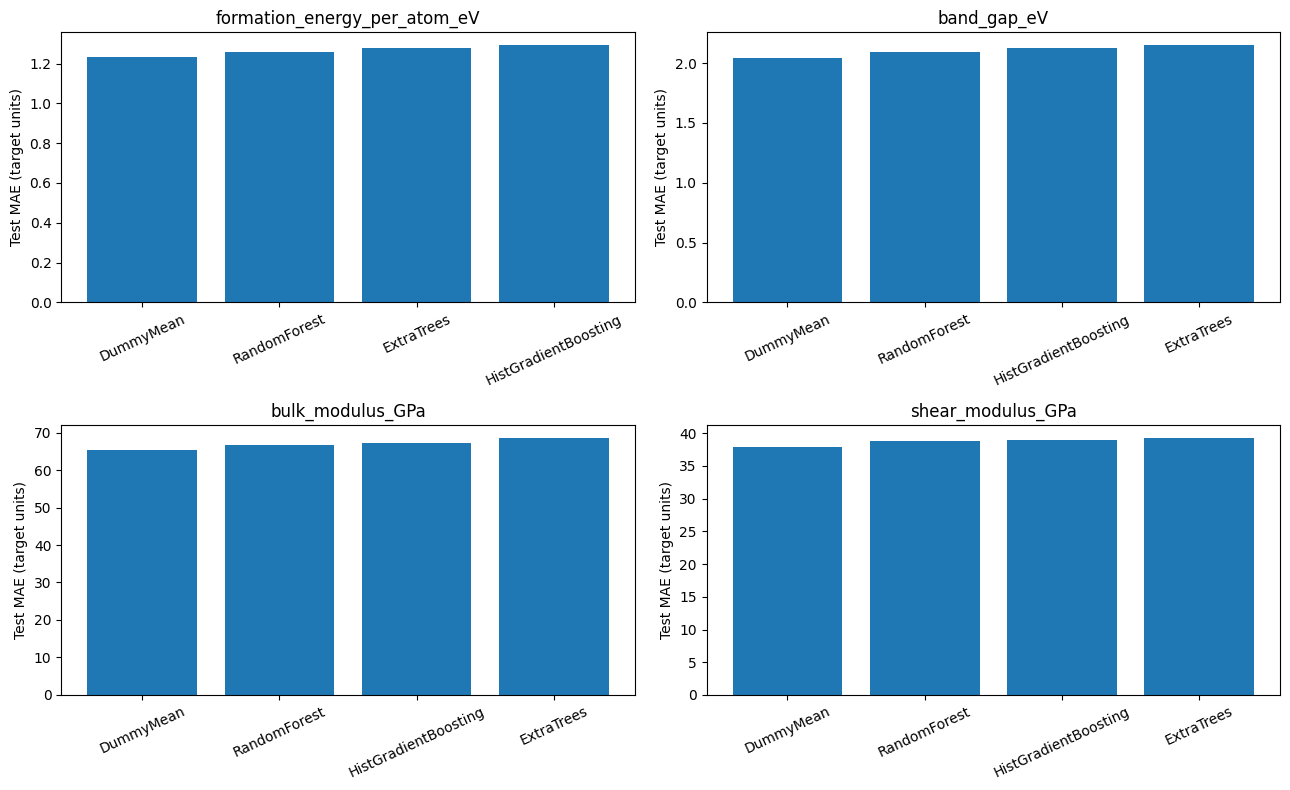

Saved outputs to C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\ML\notebooks\outputs\ds1_baseline


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, target in zip(axes.flat, TARGETS):
    subset = results[results.target == target].sort_values("MAE")
    ax.bar(subset["model"], subset["MAE"])
    ax.set_title(target)
    ax.set_ylabel("Test MAE (target units)")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

# Keep the historical DS1 exports and satisfy the consolidated registry contract.
LEGACY_OUTPUT_DIR = Path("outputs/ds1_baseline")
LEGACY_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
results.to_csv(LEGACY_OUTPUT_DIR / "model_comparison.csv", index=False)
pd.Series(audit, name="value").to_csv(LEGACY_OUTPUT_DIR / "data_quality_audit.csv")
PROJECT_ROOT = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "ML").is_dir() and (p / "Data").is_dir()
)
OUTPUT_DIR = PROJECT_ROOT / "ML" / "outputs" / "notebook_01"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
results.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
summary = {
    "notebook": "01_ds1_material_properties_baseline",
    "dataset_path": str(DATA_PATH.resolve()),
    "rows_total": int(len(df)),
    "rows_modelled": int(len(eligible_idx)),
    "train_rows": int(len(train_rows)),
    "test_rows": int(len(test_rows)),
    "connected_groups": int(split_groups.nunique()),
    "group_overlap": 0,
    "chemical_system_overlap": 0,
    "material_id_overlap": 0,
    "targets": TARGETS,
    "selection_note": "Single grouped holdout comparison; exploratory baseline, not production validation.",
    "outputs": ["metrics.csv", "run_summary.json"],
}
(OUTPUT_DIR / "run_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Saved registry outputs to", OUTPUT_DIR.resolve())


6. Interpretation and go/no-go criteria
Use the metrics table rather than selecting a model by name. A model is not useful merely because it is more complex. Compare each model with DummyMean; negative test R² means it performs worse than predicting the test-set mean under this split.
Before using these results in a product:
1. Investigate duplicate material_id values and validate material provenance.
2. Confirm target units and physical plausibility with a domain expert.
3. Add repeated grouped cross-validation and uncertainty intervals.
4. Evaluate a separate, source-verified external dataset if available.
5. Do not call this a CGNN/PINN result: no structures are provided and this notebook only performs composition-feature regression.